# Diabetes Prediction with Decision Trees

**Goal:** build an interpretable classifier that predicts whether a patient has diabetes from basic clinical and lifestyle variables.

**Dataset:** `diabete_arbre.csv` - 53,630 patient records (9 columns: demographics, medical history, blood pressure, BMI and HbA1c).

**Workflow**

1. Setup
2. Data loading and quality checks
3. Exploratory data analysis (EDA)
4. Preprocessing and train/test split
5. Baselines (dummy classifier and unconstrained decision tree)
6. Feature importance and feature selection
7. Hyperparameter tuning with cross-validated grid search
8. Final evaluation (classification report, confusion matrix, ROC / precision-recall curves)
9. Model interpretation
10. Conclusions

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay, roc_auc_score, average_precision_score,
)

RANDOM_STATE = 51016
TARGET = "diabetes"

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

## 2. Data loading and quality checks

In [2]:
df_raw = pd.read_csv("diabete_arbre.csv", sep=";")
df_raw.head()

,sexe,hypertension,maladie_cardiaque,fumeur,pression_sang,diabete,age,imc,hba1c
0,F,0,0,non,158,0,78.0,22,6.0
1,F,0,0,non,145,0,42.0,27,6.5
2,F,0,0,non,126,0,24.0,24,4.0
3,M,0,0,oui,240,1,71.0,28,5.7
4,M,0,0,ancien,130,0,52.0,30,6.0


In [3]:
print(f"Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns\n")
df_raw.info()

Shape: 53,630 rows x 9 columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53630 entries, 0 to 53629
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sexe               53630 non-null  object 
 1   hypertension       53630 non-null  int64  
 2   maladie_cardiaque  53630 non-null  int64  
 3   fumeur             53630 non-null  object 
 4   pression_sang      53630 non-null  int64  
 5   diabete            53630 non-null  int64  
 6   age                53630 non-null  float64
 7   imc                53630 non-null  int64  
 8   hba1c              53630 non-null  float64
dtypes: float64(2), int64(5), object(2)
memory usage: 3.7+ MB


The column names are in French in the source file. They are renamed to English, and the smoking categories are translated, to make the analysis easier to read.

In [4]:
df = df_raw.rename(columns={
    "sexe": "sex",
    "maladie_cardiaque": "heart_disease",
    "fumeur": "smoking_status",
    "pression_sang": "blood_pressure",
    "diabete": "diabetes",
    "imc": "bmi",
})
df["sex"] = df["sex"].map({"F": "Female", "M": "Male"})
df["smoking_status"] = df["smoking_status"].map({"non": "never", "ancien": "former", "oui": "current"})

print("Missing values per column:")
print(df.isna().sum().to_string())

Missing values per column:
sex               0
hypertension      0
heart_disease     0
smoking_status    0
blood_pressure    0
diabetes          0
age               0
bmi               0
hba1c             0


In [5]:
n_dup = df.duplicated().sum()
print(f"Duplicated rows: {n_dup:,} ({n_dup / len(df):.1%})")

# Duplicates are removed *before* splitting so that identical rows cannot leak from train to test
df = df.drop_duplicates().reset_index(drop=True)
print(f"Shape after de-duplication: {df.shape}")

Duplicated rows: 2,231 (4.2%)
Shape after de-duplication: (51399, 9)


## 3. Exploratory data analysis

### 3.1 Target distribution

diabetes
0    0.886126
1    0.113874


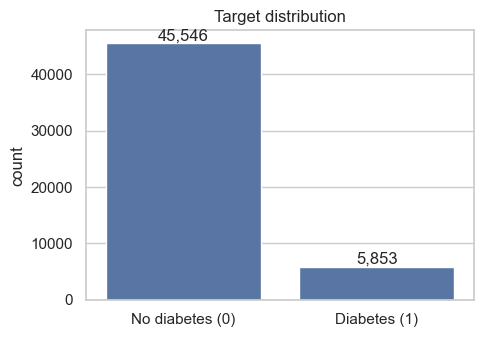

In [6]:
print(df[TARGET].value_counts(normalize=True).rename("proportion").to_string())

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x=TARGET, ax=ax)
ax.set_xticks([0, 1], ["No diabetes (0)", "Diabetes (1)"])
ax.set_xlabel("")
ax.set_title("Target distribution")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.show()

The target is **strongly imbalanced** (roughly 9 non-diabetic patients for every diabetic one). Consequently:

- accuracy alone is misleading, since a model that always predicts "no diabetes" already reaches ~89 %;
- the train/test split must be **stratified**;
- recall, F1-score and PR-AUC on the minority class must be monitored.

### 3.2 Numerical variables

In [7]:
num_cols = ["age", "bmi", "hba1c", "blood_pressure"]
cat_cols = ["sex", "smoking_status", "hypertension", "heart_disease"]
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,51399.0,46.32,19.54,0.16,31.0,47.0,61.0,80.0
bmi,51399.0,28.46,6.67,10.00,24.0,27.0,31.0,92.0
hba1c,51399.0,5.57,1.10,3.50,4.8,5.8,6.2,9.0
blood_pressure,51399.0,139.90,42.43,80.00,100.0,140.0,159.0,300.0


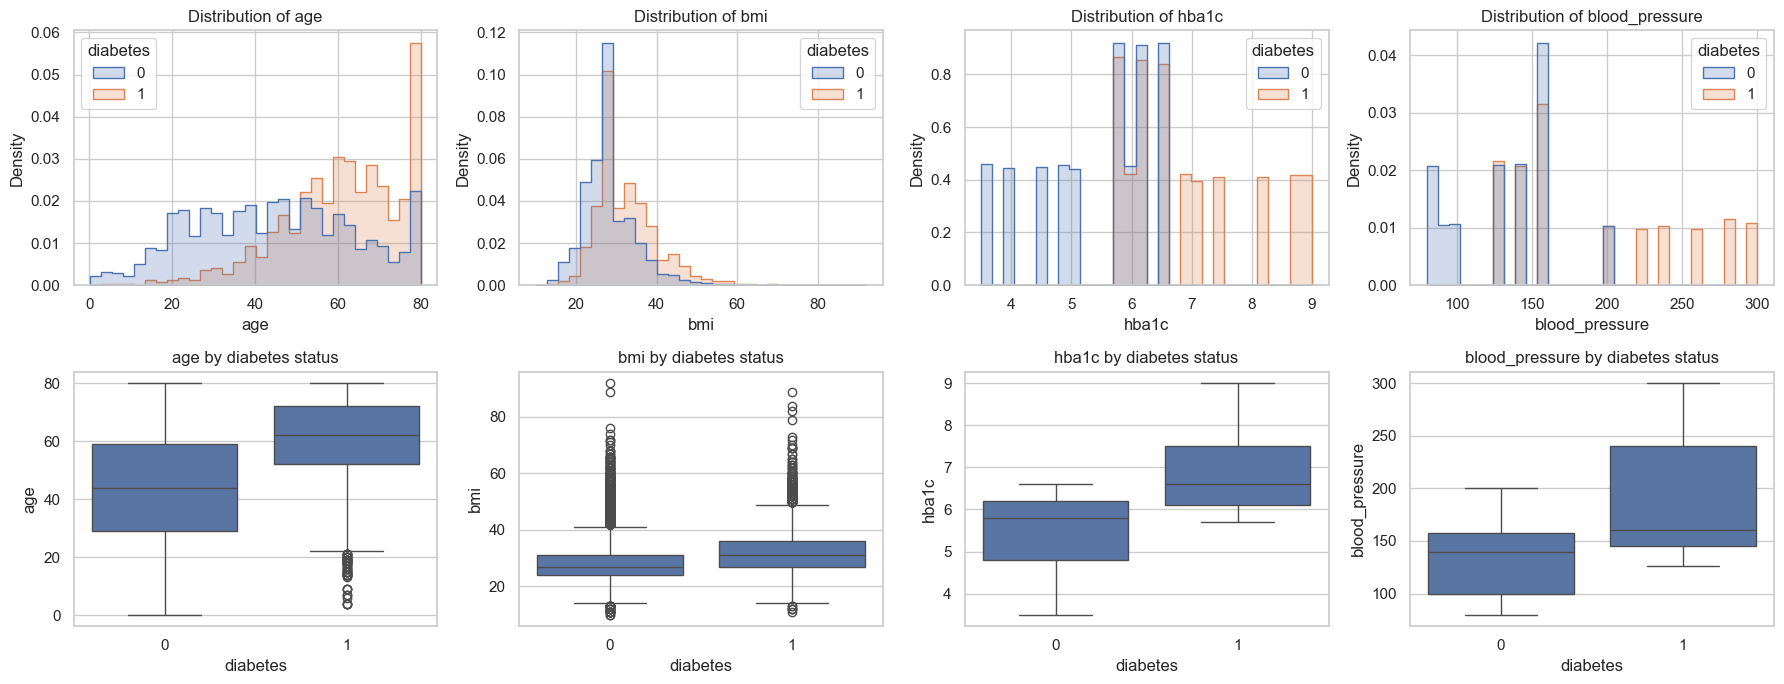

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, hue=TARGET, bins=30, stat="density",
                 common_norm=False, element="step", ax=axes[0, i])
    axes[0, i].set_title(f"Distribution of {col}")
    sns.boxplot(data=df, x=TARGET, y=col, ax=axes[1, i])
    axes[1, i].set_title(f"{col} by diabetes status")
plt.tight_layout()
plt.show()

In [9]:
# Outlier check with the 1.5 x IQR rule
rows = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)
    rows.append({"variable": col, "n_outliers": int(mask.sum()), "share": f"{mask.mean():.1%}"})
pd.DataFrame(rows)

,variable,n_outliers,share
0,age,0,0.0%
1,bmi,2456,4.8%
2,hba1c,899,1.7%
3,blood_pressure,1380,2.7%


Tree-based models are insensitive to monotonic transformations and to outliers (splits depend only on the ordering of values), so **no scaling or outlier removal is required** here.

### 3.3 Categorical and binary variables

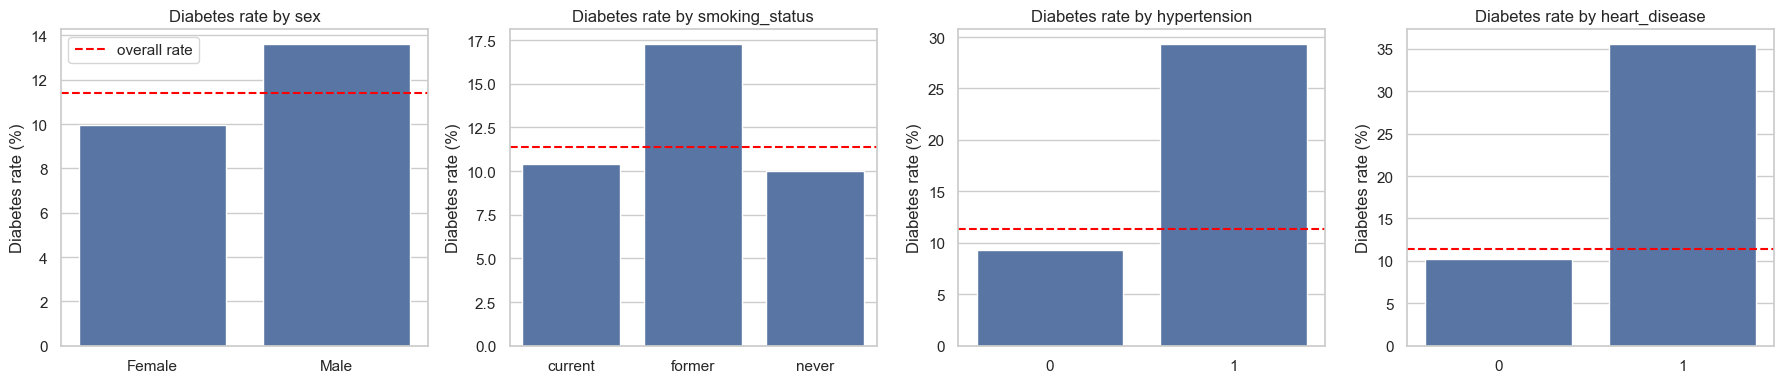

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, cat_cols):
    rate = df.groupby(col)[TARGET].mean().mul(100)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)
    ax.axhline(df[TARGET].mean() * 100, color="red", linestyle="--", label="overall rate")
    ax.set_title(f"Diabetes rate by {col}")
    ax.set_ylabel("Diabetes rate (%)")
    ax.set_xlabel("")
axes[0].legend()
plt.tight_layout()
plt.show()

### 3.4 Correlations

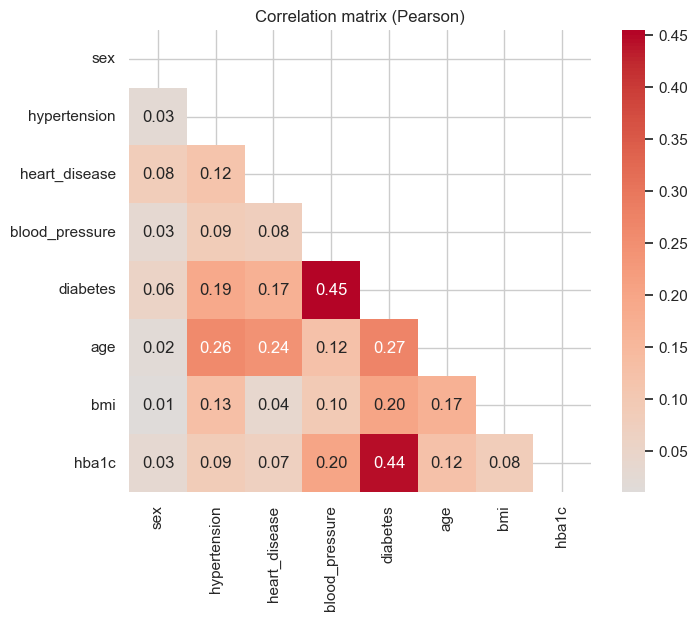

Correlation with the target:
blood_pressure    0.454
hba1c             0.443
age               0.272
bmi               0.202
hypertension      0.192
heart_disease     0.168
sex               0.056


In [11]:
corr = (
    df.assign(sex=df["sex"].eq("Male").astype(int))
      .drop(columns="smoking_status")
      .corr()
)
fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=ax)
ax.set_title("Correlation matrix (Pearson)")
plt.show()

print("Correlation with the target:")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_string())

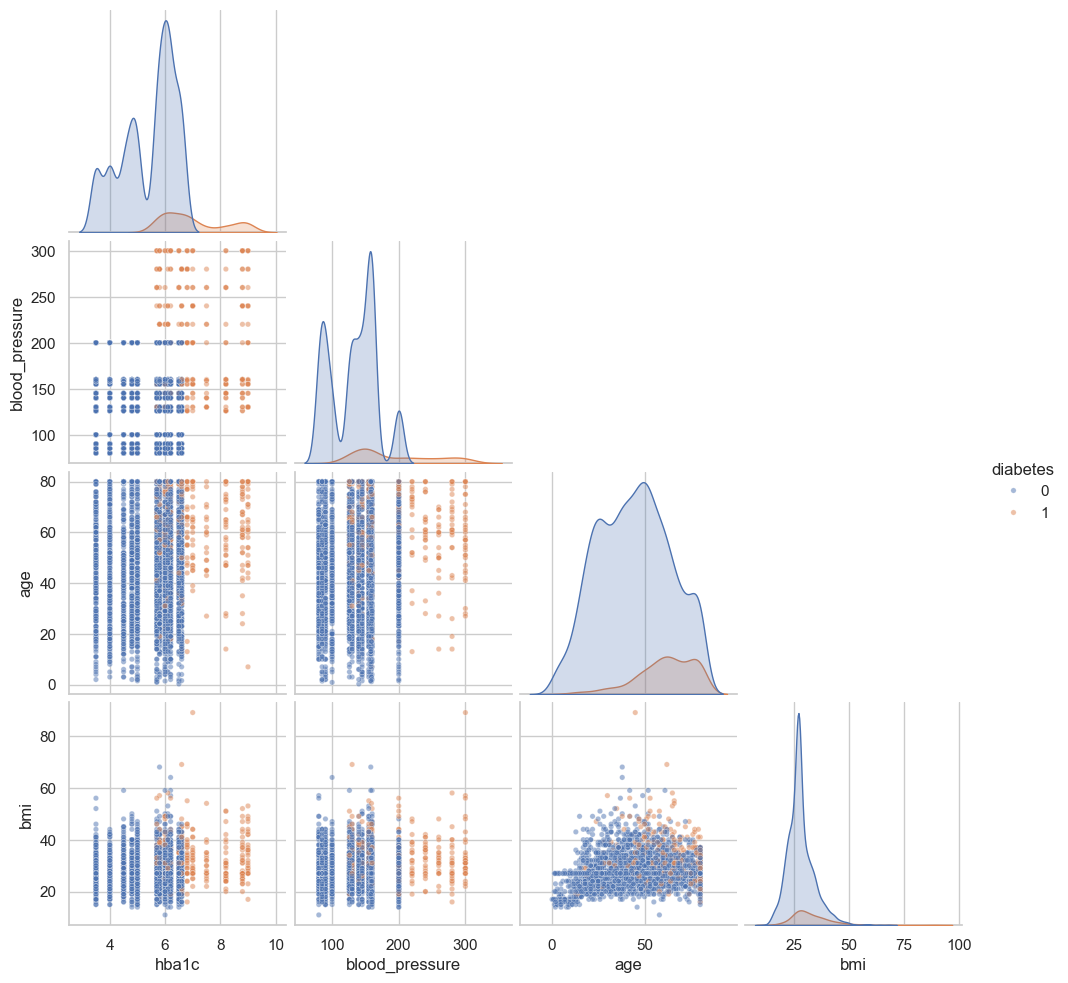

In [12]:
sns.pairplot(df.sample(3000, random_state=RANDOM_STATE), vars=["hba1c", "blood_pressure", "age", "bmi"],
             hue=TARGET, corner=True, plot_kws={"alpha": 0.5, "s": 15})
plt.show()

## 4. Preprocessing and train/test split

- `sex` is encoded as a binary variable (`is_male`).
- `smoking_status` is one-hot encoded (the categories are nominal), with `never` as the reference level.
- The data is split **80/20 with stratification** on the target so that the class ratio is preserved in both sets.

In [13]:
data = df.copy()
data["is_male"] = data["sex"].eq("Male").astype(int)
data = pd.get_dummies(data, columns=["smoking_status"], dtype=int).drop(columns=["sex", "smoking_status_never"])

X = data.drop(columns=TARGET)
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")
print(f"Positive rate - train: {y_train.mean():.3%}  |  test: {y_test.mean():.3%}")
X_train.head()

Train: (41119, 9)  |  Test: (10280, 9)
Positive rate - train: 11.386%  |  test: 11.391%


,hypertension,heart_disease,blood_pressure,age,bmi,hba1c,is_male,smoking_status_current,smoking_status_former
8859,0,0,155,55.0,37,6.8,0,0,0
33263,0,0,85,49.0,24,4.8,1,0,0
23274,0,0,160,77.0,27,8.8,0,0,1
50578,1,1,280,61.0,45,6.0,0,0,0
51155,0,0,126,66.0,27,4.8,0,0,0


## 5. Baselines

Two reference points are used: a **dummy classifier** (always predicts the majority class) and an **unconstrained decision tree** (grown until all leaves are pure, which typically overfits).

In [14]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"Dummy classifier - test accuracy: {dummy.score(X_test, y_test):.4f}")

tree_full = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_train, y_train)
print(f"Unconstrained tree - train accuracy: {tree_full.score(X_train, y_train):.4f}")
print(f"Unconstrained tree - test accuracy:  {tree_full.score(X_test, y_test):.4f}")
print(f"Depth: {tree_full.get_depth()}  |  Leaves: {tree_full.get_n_leaves()}")

Dummy classifier - test accuracy: 0.8861
Unconstrained tree - train accuracy: 0.9986
Unconstrained tree - test accuracy:  0.9373
Depth: 30  |  Leaves: 2675


The unconstrained tree fits the training set almost perfectly but loses several points on the test set, a classic sign of **overfitting**. It has a very large number of leaves and is neither robust nor interpretable.

## 6. Feature importance and selection

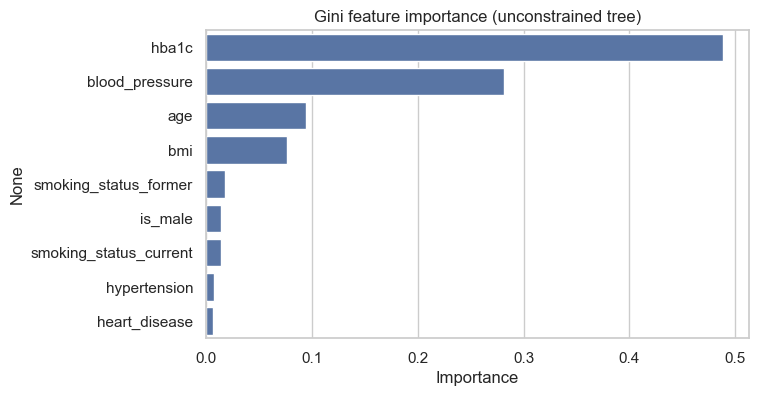

hba1c                     0.4885
blood_pressure            0.2815
age                       0.0943
bmi                       0.0762
smoking_status_former     0.0175
is_male                   0.0143
smoking_status_current    0.0142
hypertension              0.0070
heart_disease             0.0066


In [15]:
importances = (
    pd.Series(tree_full.feature_importances_, index=X_train.columns, name="importance")
      .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=importances.values, y=importances.index, ax=ax)
ax.set_title("Gini feature importance (unconstrained tree)")
ax.set_xlabel("Importance")
plt.show()

print(importances.round(4).to_string())

`hba1c` and `blood_pressure` together carry roughly 75 % of the total importance. Variables with an importance above **0.05** are kept; the others contribute little and mostly add noise and complexity.

> The importances are computed on the **training set only**, so the selection uses no information from the test set.

In [16]:
IMPORTANCE_THRESHOLD = 0.05
selected_features = importances[importances > IMPORTANCE_THRESHOLD].index.tolist()
print("Selected features:", selected_features)

X_train_sel = X_train[selected_features]
X_test_sel = X_test[selected_features]

tree_sel = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_train_sel, y_train)
print(f"Train accuracy: {tree_sel.score(X_train_sel, y_train):.4f}")
print(f"Test accuracy:  {tree_sel.score(X_test_sel, y_test):.4f}")

Selected features: ['hba1c', 'blood_pressure', 'age', 'bmi']
Train accuracy: 0.9924
Test accuracy:  0.9391


## 7. Hyperparameter tuning

A grid search with **5-fold stratified cross-validation** is run on the training set only. Because the classes are imbalanced, models are ranked on the **F1-score of the positive class** rather than accuracy, which would favour models that ignore diabetic patients.

In [17]:
param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": np.arange(2, 11),
    "min_samples_split": [2, 10, 50],
    "min_samples_leaf": [1, 5, 20],
    "class_weight": [None, "balanced"],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid, cv=cv, scoring="f1", n_jobs=-1, verbose=1,
)
grid.fit(X_train_sel, y_train)

print("Best parameters:", grid.best_params_)
print(f"Best cross-validated F1: {grid.best_score_:.4f}")

Fitting 5 folds for each of 324 candidates, totalling 1620 fits


Best parameters: {'class_weight': None, 'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 20, 'min_samples_split': 50}
Best cross-validated F1: 0.7983


In [18]:
cv_results = pd.DataFrame(grid.cv_results_).sort_values("rank_test_score")
cv_results[["rank_test_score", "mean_test_score", "std_test_score", "param_max_depth",
            "param_criterion", "param_class_weight", "param_min_samples_leaf",
            "param_min_samples_split"]].head(10).round(4).reset_index(drop=True)

,rank_test_score,mean_test_score,std_test_score,param_max_depth,param_criterion,param_class_weight,param_min_samples_leaf,param_min_samples_split
0,1,0.7983,0.0029,10,gini,None,20,50
1,2,0.7980,0.0020,10,gini,None,20,10
2,2,0.7980,0.0020,10,gini,None,20,2
3,4,0.7974,0.0023,10,gini,None,5,50
4,5,0.7974,0.0054,7,gini,None,20,2
5,5,0.7974,0.0054,7,gini,None,20,50
6,5,0.7974,0.0054,7,gini,None,20,10
7,5,0.7974,0.0054,7,gini,None,1,2
8,5,0.7974,0.0054,7,gini,None,1,10
9,5,0.7974,0.0054,7,gini,None,5,2


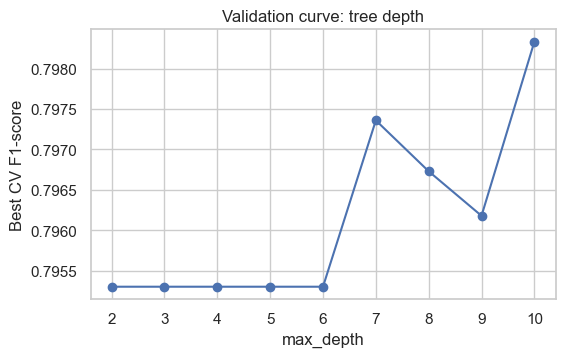

In [19]:
# Effect of tree depth on cross-validated F1 (best score for each depth)
depth_curve = cv_results.groupby("param_max_depth")["mean_test_score"].max()

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(depth_curve.index.astype(int), depth_curve.values, marker="o")
ax.set_xlabel("max_depth")
ax.set_ylabel("Best CV F1-score")
ax.set_title("Validation curve: tree depth")
plt.show()

## 8. Final evaluation on the test set

In [20]:
best_tree = grid.best_estimator_
y_pred = best_tree.predict(X_test_sel)
y_proba = best_tree.predict_proba(X_test_sel)[:, 1]

print(f"Train accuracy: {best_tree.score(X_train_sel, y_train):.4f}")
print(f"Test accuracy:  {best_tree.score(X_test_sel, y_test):.4f}")
print(f"ROC-AUC:        {roc_auc_score(y_test, y_proba):.4f}")
print(f"PR-AUC (AP):    {average_precision_score(y_test, y_proba):.4f}\n")
print(classification_report(y_test, y_pred, target_names=["No diabetes", "Diabetes"]))

Train accuracy: 0.9623
Test accuracy:  0.9626
ROC-AUC:        0.9732
PR-AUC (AP):    0.8848

              precision    recall  f1-score   support

 No diabetes       0.96      1.00      0.98      9109
    Diabetes       0.96      0.70      0.81      1171

    accuracy                           0.96     10280
   macro avg       0.96      0.85      0.89     10280
weighted avg       0.96      0.96      0.96     10280



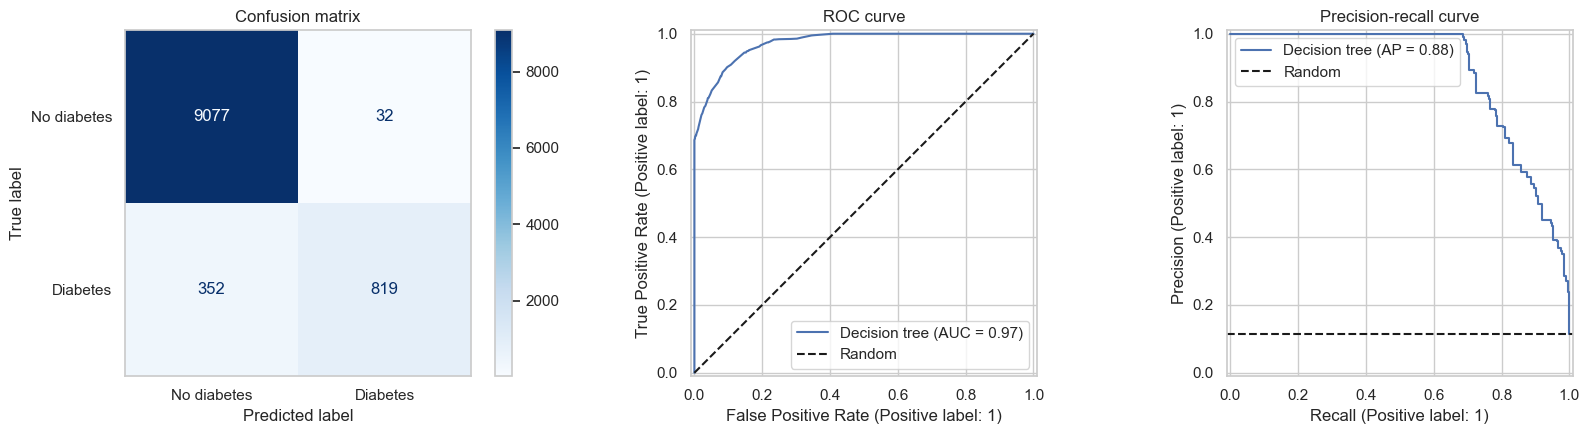

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["No diabetes", "Diabetes"], cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion matrix")
axes[0].grid(False)

RocCurveDisplay.from_predictions(y_test, y_proba, name="Decision tree", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Random")
axes[1].set_title("ROC curve")
axes[1].legend()

PrecisionRecallDisplay.from_predictions(y_test, y_proba, name="Decision tree", ax=axes[2])
axes[2].axhline(y_test.mean(), color="k", linestyle="--", label="Random")
axes[2].set_title("Precision-recall curve")
axes[2].legend()

plt.tight_layout()
plt.show()

### Summary of all models

In [22]:
def summarize(name, model, X_tr, X_te):
    pred = model.predict(X_te)
    rep = classification_report(y_test, pred, output_dict=True)["1"]
    return {
        "model": name,
        "train_acc": model.score(X_tr, y_train),
        "test_acc": model.score(X_te, y_test),
        "precision (class 1)": rep["precision"],
        "recall (class 1)": rep["recall"],
        "f1 (class 1)": rep["f1-score"],
    }

pd.DataFrame([
    summarize("Dummy (majority class)", dummy, X_train, X_test),
    summarize("Tree - all features, no tuning", tree_full, X_train, X_test),
    summarize("Tree - selected features, no tuning", tree_sel, X_train_sel, X_test_sel),
    summarize("Tree - selected features, tuned", best_tree, X_train_sel, X_test_sel),
]).set_index("model").round(4)

,train_acc,test_acc,precision (class 1),recall (class 1),f1 (class 1)
model,,,,,
Dummy (majority class),0.8861,0.8861,0.0000,0.0000,0.0000
"Tree - all features, no tuning",0.9986,0.9373,0.7097,0.7600,0.7340
"Tree - selected features, no tuning",0.9924,0.9391,0.7250,0.7498,0.7372
"Tree - selected features, tuned",0.9623,0.9626,0.9624,0.6994,0.8101


## 9. Model interpretation

Only the first three levels of the tuned tree are displayed for readability.

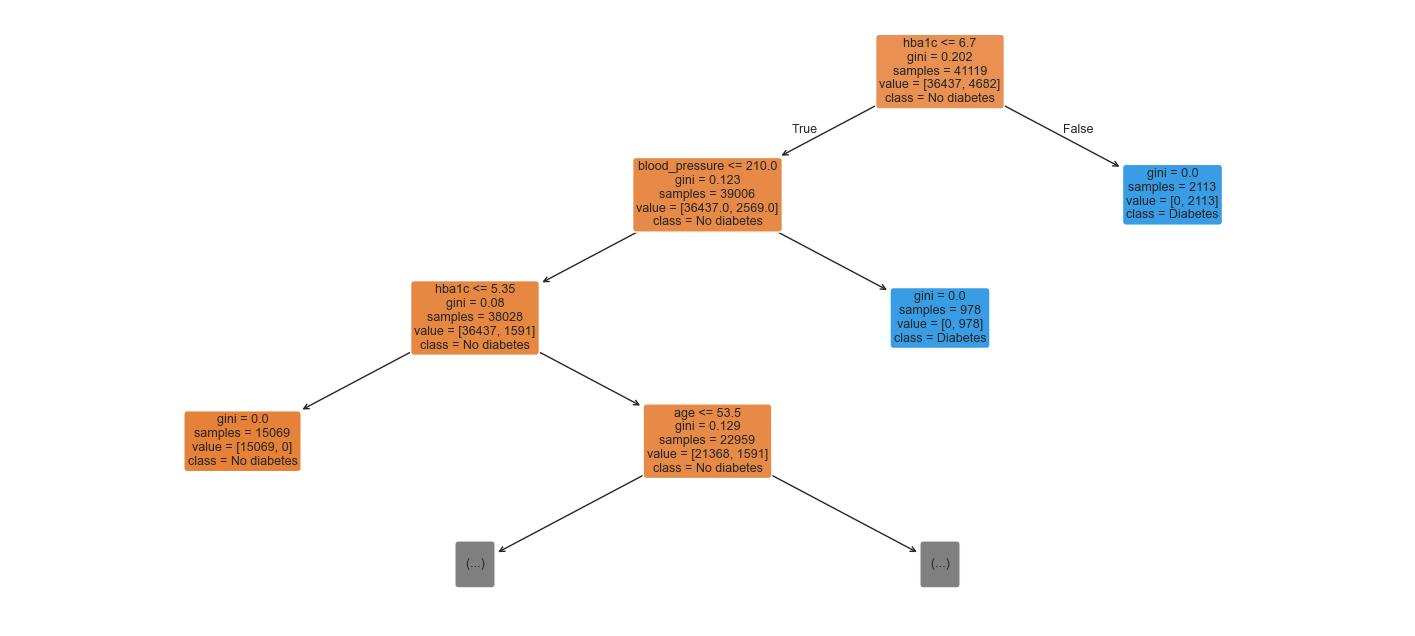

In [23]:
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(best_tree, max_depth=3, feature_names=selected_features, class_names=["No diabetes", "Diabetes"],
          filled=True, rounded=True, fontsize=9, ax=ax)
plt.show()

In [24]:
# Only the first levels are displayed; the full tree is deeper (see best_tree.get_depth())
print(export_text(best_tree, feature_names=selected_features, max_depth=3))

|--- hba1c <= 6.70
|   |--- blood_pressure <= 210.00
|   |   |--- hba1c <= 5.35
|   |   |   |--- class: 0
|   |   |--- hba1c >  5.35
|   |   |   |--- age <= 53.50
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- age >  53.50
|   |   |   |   |--- truncated branch of depth 7
|   |--- blood_pressure >  210.00
|   |   |--- class: 1
|--- hba1c >  6.70
|   |--- class: 1



## 10. Conclusions

**Key findings**

- **HbA1c and blood pressure are the dominant predictors**, followed by age and BMI. Smoking status, sex, hypertension and heart disease add very little once these four variables are known.
- An unconstrained tree overfits (train accuracy ~99.9 % vs ~93.7 % on the test set). Feature selection and, above all, regularisation (`max_depth`, `min_samples_leaf`, `min_samples_split`) close the gap: the tuned tree reaches **~96.3 % test accuracy with no train/test gap**, ROC-AUC ~0.97 and PR-AUC ~0.88.
- Accuracy alone is not informative here (the majority-class baseline already scores ~88.6 %). On the minority class, the tuned tree reaches a **precision of ~0.96, a recall of ~0.70 and an F1-score of ~0.81**, versus an F1-score of ~0.74 for the untuned trees.

**Limitations and next steps**

- Recall on diabetic patients (~70 %) is the main weakness: about three in ten diabetic patients are missed. In a screening context, false negatives are costlier than false positives, so the decision threshold (or `class_weight`) should be tuned to favour recall, accepting some loss in precision.
- The best configurations in the grid search differ by less than the cross-validation standard deviation, so the selected hyperparameters should not be over-interpreted.
- A single train/test split was used; repeated cross-validation would give a more robust estimate of the generalisation error.
- Ensemble methods (Random Forest, Gradient Boosting) usually improve on a single tree at the cost of interpretability, and are a natural next step.
- The dataset has no information on its origin or collection protocol. This work is educational and the model must not be used for medical decisions.